# Projet 0 : prise en main de Python, pandas et des graphiques

[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Lucfunazzi/machine-learning-projets/blob/main/00_prise_en_main.ipynb)

**Objectif :** apprendre les gestes de base utilisés dans tous les projets suivants : charger un tableau de données, l'explorer, le nettoyer, calculer des statistiques et tracer des graphiques.

**Données :** pour ce premier projet, on utilise un petit jeu de données **simulé** (fictif), créé dans le notebook. Il imite une mini-expérience de psychologie cognitive (âge, sommeil, temps de réaction). Les projets suivants utiliseront de vraies données ouvertes, avec leur source et leur licence.

**Plan :**
1. Créer et regarder un tableau
2. Sélectionner et filtrer
3. Statistiques de base et regroupements
4. Valeurs manquantes
5. Graphiques
6. Corrélations
7. Conclusion et exercices

## 1. Créer et regarder un tableau

`pandas` est la bibliothèque Python pour manipuler des tableaux de données (appelés *DataFrame*). `numpy` sert aux calculs, `matplotlib` aux graphiques.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

On génère 60 participants fictifs. La ligne `np.random.default_rng(42)` fixe la « graine » du hasard : tout le monde obtient exactement les mêmes données (c'est le même principe que `random_state=42` dans scikit-learn).

In [67]:
rng = np.random.default_rng(42)
n = 60

age = rng.integers(18, 70, size=n)
sommeil = np.round(rng.normal(7, 1, size=n), 1)            # heures de sommeil
etudes = rng.choice(["Bac", "Licence", "Master", "Doctorat"], size=n, p=[0.3, 0.35, 0.25, 0.1])
tranche_age = pd.cut(age, bins=[18, 30, 50, 70], labels=["18-30", "31-50", "51-70"], include_lowest=True)

# temps de réaction en millisecondes : augmente avec l'âge, diminue avec le sommeil, plus du bruit
temps_reaction = np.round(250 + 1.8 * age - 8 * (sommeil - 7) + rng.normal(0, 15, size=n), 0)

df = pd.DataFrame({
    "age": age,
    "sommeil_h": sommeil,
    "etudes": etudes,
    "temps_reaction_ms": temps_reaction,
    "tranche_age": tranche_age
})
df.head()

,age,sommeil_h,etudes,temps_reaction_ms,tranche_age
0,22,9.1,Licence,270.0,18-30
1,58,6.6,Licence,342.0,51-70
2,52,6.5,Licence,322.0,51-70
3,40,6.2,Licence,321.0,31-50
4,40,7.6,Licence,316.0,31-50


- `df.head()` affiche les 5 premières lignes.
- Chaque **ligne** est un participant, chaque **colonne** une variable.

In [3]:
print("Dimensions (lignes, colonnes) :", df.shape)
df.info()

Dimensions (lignes, colonnes) : (60, 4)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   age                60 non-null     int64  
 1   sommeil_h          60 non-null     float64
 2   etudes             60 non-null     object 
 3   temps_reaction_ms  60 non-null     float64
dtypes: float64(2), int64(1), object(1)
memory usage: 2.0+ KB


`df.info()` indique le type de chaque colonne (`int64` : entier, `float64` : nombre décimal, `object` ou `str` : texte, selon la version de pandas) et le nombre de valeurs renseignées.

## 2. Sélectionner et filtrer

In [4]:
# Une colonne
df["age"].head()

,age
0,22
1,58
2,52
3,40
4,40


In [5]:
# Plusieurs colonnes
df[["age", "temps_reaction_ms"]].head()

,age,temps_reaction_ms
0,22,270.0
1,58,342.0
2,52,322.0
3,40,321.0
4,40,316.0


In [6]:
# Filtrer : les participants de plus de 50 ans
df[df["age"] > 50].head()

,age,sommeil_h,etudes,temps_reaction_ms
1,58,6.6,Licence,342.0
2,52,6.5,Licence,322.0
5,62,8.1,Bac,379.0
7,54,6.2,Doctorat,368.0
11,68,7.5,Doctorat,358.0


In [7]:
# Combiner deux conditions (& = et, | = ou)
df[(df["age"] > 50) & (df["sommeil_h"] < 6.5)]

,age,sommeil_h,etudes,temps_reaction_ms
7,54,6.2,Doctorat,368.0
12,56,6.3,Master,388.0
25,51,6.4,Master,349.0
41,57,5.9,Licence,359.0
42,54,6.1,Licence,349.0


## 3. Statistiques de base et regroupements

In [25]:
df.describe()

,age,sommeil_h,temps_reaction_ms
count,60.000000,60.000000,60.000000
mean,44.833333,7.005000,330.233333
std,14.364701,0.750689,28.762244
min,20.000000,5.300000,266.000000
25%,35.000000,6.500000,314.750000
50%,45.500000,7.100000,337.000000
75%,57.000000,7.600000,352.250000
max,68.000000,9.100000,388.000000


`describe()` donne pour chaque variable numérique : effectif, moyenne, écart-type, minimum, quartiles et maximum. Ces notions reviendront dans le cours (la standardisation utilise la moyenne et l'écart-type).

In [9]:
# Moyenne du temps de réaction selon le niveau d'études
df.groupby("etudes")["temps_reaction_ms"].mean().round(1)

,temps_reaction_ms
etudes,
Bac,323.8
Doctorat,330.3
Licence,331.4
Master,338.0


In [10]:
# Nombre de participants par niveau d'études
df["etudes"].value_counts()

,count
etudes,
Licence,28
Bac,16
Master,9
Doctorat,7


## 4. Valeurs manquantes

Dans la vraie vie, les données sont rarement complètes. Simulons-en quelques-unes pour apprendre à les gérer.

In [11]:
df_na = df.copy()
df_na.loc[[3, 10, 25], "sommeil_h"] = np.nan   # NaN = valeur manquante
df_na.isna().sum()

,0
age,0
sommeil_h,3
etudes,0
temps_reaction_ms,0


In [12]:
# Option 1 : supprimer les lignes incomplètes
df_sans_na = df_na.dropna()
print(len(df_na), "->", len(df_sans_na), "lignes")

# Option 2 : remplacer par la médiane de la colonne
df_rempli = df_na.fillna({"sommeil_h": df_na["sommeil_h"].median()})
df_rempli.isna().sum()

60 -> 57 lignes


,0
age,0
sommeil_h,0
etudes,0
temps_reaction_ms,0


Il n'y a pas de bonne réponse universelle : supprimer fait perdre des données, remplacer en invente un peu. L'important est de **savoir ce qu'on a fait et de le dire**.

## 5. Graphiques

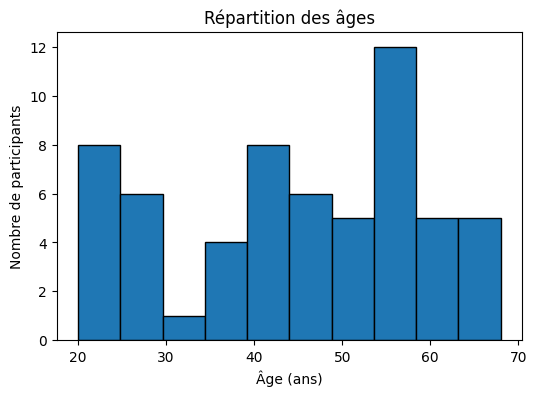

In [13]:
plt.figure(figsize=(6, 4))
plt.hist(df["age"], bins=10, edgecolor="black")
plt.xlabel("Âge (ans)")
plt.ylabel("Nombre de participants")
plt.title("Répartition des âges")
plt.show()

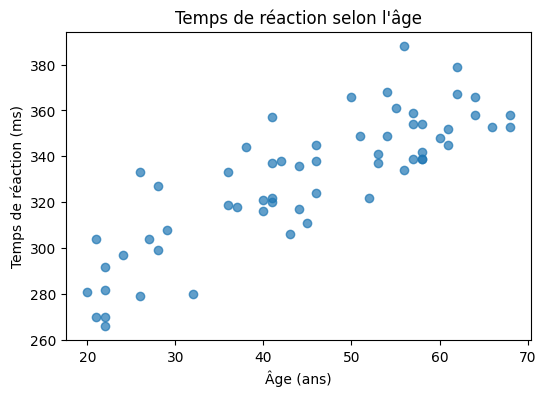

In [14]:
plt.figure(figsize=(6, 4))
plt.scatter(df["age"], df["temps_reaction_ms"], alpha=0.7)
plt.xlabel("Âge (ans)")
plt.ylabel("Temps de réaction (ms)")
plt.title("Temps de réaction selon l'âge")
plt.show()

Ce nuage de points ressemble beaucoup à ceux du cours (surface → prix) : c'est exactement le type de relation qu'une **régression linéaire** cherchera à décrire dans le projet 1.

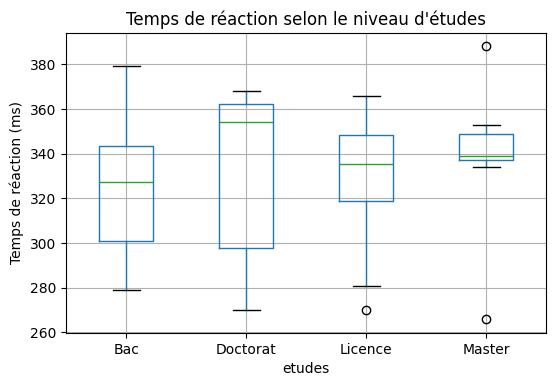

In [15]:
df.boxplot(column="temps_reaction_ms", by="etudes", figsize=(6, 4))
plt.suptitle("")
plt.title("Temps de réaction selon le niveau d'études")
plt.ylabel("Temps de réaction (ms)")
plt.show()

## 6. Corrélations

La corrélation mesure à quel point deux variables varient ensemble (de -1 à +1).

In [ ]:
corr = df[["age", "sommeil_h", "temps_reaction_ms"]].corr().round(2)
corr

In [ ]:
plt.figure(figsize=(5, 4))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, corr.iloc[i, j], ha="center", va="center")
plt.title("Matrice de corrélation")
plt.show()

# Exercice 1







In [24]:
df.sort_values("temps_reaction_ms").head(10)

,age,sommeil_h,etudes,temps_reaction_ms
9,22,7.7,Master,266.0
0,22,9.1,Licence,270.0
44,21,7.1,Doctorat,270.0
57,26,7.0,Bac,279.0
38,32,7.9,Bac,280.0
55,20,7.5,Licence,281.0
32,22,7.2,Bac,282.0
6,22,6.9,Bac,292.0
17,24,7.2,Doctorat,297.0
8,28,6.2,Doctorat,299.0


# Exercice 2



In [61]:
age_moyen = df[df["etudes"] == "Master"]["age"].mean().round(2)
age_moyen

np.float64(51.11)

## 7. Conclusion

*(à compléter avec tes mots)*

Dans ce jeu simulé, le temps de réaction est fortement corrélé à l'âge (corrélation positive) et faiblement au sommeil (corrélation négative). Attention : une corrélation n'est **pas** une causalité, et ces données sont fictives, donc ce résultat ne dit rien sur le monde réel.

## Exercices pour t'entraîner

1. Affiche les 10 participants au temps de réaction le plus faible (indice : `df.sort_values(...)`).
2. Calcule l'âge moyen des participants ayant un Master.
3. Crée une nouvelle colonne `tranche_age` avec `pd.cut` (18-30, 31-50, 51-70) et compare les temps de réaction moyens par tranche.
4. Trace un nuage de points `sommeil_h` vs `temps_reaction_ms`. La relation est-elle visible ? Pourquoi est-elle plus difficile à voir que pour l'âge ?